# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

**Autor:** David Pilataxi  
**Fecha:** 28 de octubre de 2026



In [1]:
import sys, re, unicodedata, time, statistics, platform, json, pickle, gc
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
DATA = Path('datos_booleansearch')
DATA.mkdir(exist_ok=True)
nltk.download('gutenberg', download_dir=str(DATA / 'nltk'), quiet=True, raise_on_error=True)
nltk.data.path.insert(0, str(DATA / 'nltk'))
from nltk.corpus import gutenberg
def normalizar(texto):
    # NFC conserva letras acentuadas; se excluyen números, puntuación y guiones bajos.
    return [sys.intern(t) for t in re.findall(r'[^\W\d_]+', unicodedata.normalize('NFC', texto).lower(), flags=re.UNICODE)]
def termino_unico(consulta):
    tokens = normalizar(consulta)
    if len(tokens) != 1:
        raise ValueError('Se requiere exactamente un término normalizado.')
    return tokens[0]
originales = {doc: gutenberg.raw(doc) for doc in gutenberg.fileids()}
corpus_a = {doc: normalizar(texto) for doc, texto in originales.items()}
assert len(corpus_a) == 18
display(pd.DataFrame([{'documento': d, 'caracteres': len(t), 'bytes_utf8': len(t.encode('utf-8')), 'tokens': len(corpus_a[d])} for d,t in originales.items()]))
print('Documentos:', len(corpus_a), '| Tokens:', sum(map(len, corpus_a.values())))
print('Ejecución real:', datetime.now().isoformat(timespec='seconds'), '| Python:', sys.version, '| Equipo:', platform.platform())
display(Markdown('**Preprocesamiento:** Unicode NFC, minúsculas y secuencias de letras Unicode. Se conservan stopwords y acentos; no se aplica stemming. Los apóstrofos y guiones separan tokens. Esta misma función se utiliza en todos los corpus y consultas.'))

,documento,caracteres,bytes_utf8,tokens
0,austen-emma.txt,887071,887071,161975
1,austen-persuasion.txt,466292,466292,84123
2,austen-sense.txt,673022,673022,120734
3,bible-kjv.txt,4332554,4332554,791842
4,blake-poems.txt,38153,38153,6934
5,bryant-stories.txt,249439,249439,46697
6,burgess-busterbrown.txt,84663,84663,16353
7,carroll-alice.txt,144395,144395,27335
8,chesterton-ball.txt,457450,457455,82785
9,chesterton-brown.txt,406629,406629,73286


Documentos: 18 | Tokens: 2136074
Ejecución real: 2026-10-28T09:37:43 | Python: 3.12.9 (tags/v3.12.9:fdb8142, Feb  4 2025, 15:27:58) [MSC v.1942 64 bit (AMD64)] | Equipo: Windows-11-10.0.26200-SP0


**Preprocesamiento:** Unicode NFC, minúsculas y secuencias de letras Unicode. Se conservan stopwords y acentos; no se aplica stemming. Los apóstrofos y guiones separan tokens. Esta misma función se utiliza en todos los corpus y consultas.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [2]:
def busqueda_secuencial(termino, corpus):
    termino = termino_unico(termino)
    encontrados = set()
    for documento, tokens in corpus.items():
        for token in tokens:
            if token == termino:
                encontrados.add(documento)
                break
    return encontrados
consultas = {'frecuente': 'the', 'poco frecuente': 'abstruse', 'inexistente': 'zzzzterminoinexistentezzzz'}
for tipo, consulta in consultas.items():
    print(tipo, consulta, sorted(busqueda_secuencial(consulta, corpus_a)))

frecuente the ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
poco frecuente abstruse ['austen-sense.txt', 'milton-paradise.txt']
inexistente zzzzterminoinexistentezzzz []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [3]:
REPETICIONES = 30
def medir(funcion, *args):
    funcion(*args)  # calentamiento excluido
    muestras = []
    for _ in range(REPETICIONES):
        inicio = time.perf_counter_ns()
        funcion(*args)
        muestras.append((time.perf_counter_ns() - inicio) / 1e6)
    return {'media_ms': statistics.mean(muestras), 'desviacion_ms': statistics.stdev(muestras), 'repeticiones': len(muestras)}
display(pd.DataFrame([{'consulta': q, **medir(busqueda_secuencial, q, corpus_a)} for q in consultas.values()]))

,consulta,media_ms,desviacion_ms,repeticiones
0,the,0.013320,0.001919,30
1,abstruse,73.482010,8.558241,30
2,zzzzterminoinexistentezzzz,76.092283,2.550727,30


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [4]:
def construir_indice(corpus):
    indice = defaultdict(set)
    for documento, tokens in corpus.items():
        for token in set(tokens):
            indice[token].add(documento)
    return dict(indice)
def busqueda_indice(termino, indice):
    return set(indice.get(termino_unico(termino), ()))
def booleana(consulta, buscar, universo):
    # Gramática: OR < AND < NOT; permite paréntesis y rechaza sintaxis incompleta.
    tokens = re.findall(r'\(|\)|[^\W\d_]+', consulta, re.UNICODE)
    if re.sub(r'\(|\)|[^\W\d_]+|\s+', '', consulta, flags=re.UNICODE):
        raise ValueError('Carácter no admitido en la consulta.')
    pos = 0
    def atom():
        nonlocal pos
        if pos >= len(tokens): raise ValueError('Falta un operando.')
        t = tokens[pos]; pos += 1
        if t == 'NOT': return universo - atom()
        if t == '(':
            resultado = disyuncion()
            if pos >= len(tokens) or tokens[pos] != ')': raise ValueError('Falta cerrar paréntesis.')
            pos += 1
            return resultado
        if t in ('AND', 'OR', ')'): raise ValueError('Operando inválido.')
        return buscar(t)
    def conjuncion():
        nonlocal pos
        r = atom()
        while pos < len(tokens) and tokens[pos] == 'AND':
            pos += 1; r &= atom()
        return r
    def disyuncion():
        nonlocal pos
        r = conjuncion()
        while pos < len(tokens) and tokens[pos] == 'OR':
            pos += 1; r |= conjuncion()
        return r
    r = disyuncion()
    if pos != len(tokens): raise ValueError('Falta un operador.')
    return r
indice_a = construir_indice(corpus_a)
print('Vocabulario:', len(indice_a))
for q in consultas.values():
    print(q, 'DF =', len(indice_a.get(q, ())), 'postings =', sorted(indice_a.get(q, ())))
booleanas = ['love AND death', 'love OR death', 'NOT love', '(love OR death) AND NOT war']
for q in booleanas:
    print(q, sorted(booleana(q, lambda t: busqueda_indice(t, indice_a), set(corpus_a))))
# Verificación de semántica y rechazo de consultas incompletas.
assert booleana('love AND NOT love', lambda t: busqueda_indice(t, indice_a), set(corpus_a)) == set()
assert booleana('love OR NOT love', lambda t: busqueda_indice(t, indice_a), set(corpus_a)) == set(corpus_a)

Vocabulario: 41509
the DF = 18 postings = ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
abstruse DF = 2 postings = ['austen-sense.txt', 'milton-paradise.txt']
zzzzterminoinexistentezzzz DF = 0 postings = []
love AND death ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']
love OR death ['austen-emma.txt', 'austen-persuasion.txt', 'aus

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [5]:
def comparar(corpus, indice):
    filas = []
    for q in list(consultas.values()) + booleanas:
        if q in booleanas:
            sec = lambda: booleana(q, lambda t: busqueda_secuencial(t, corpus), set(corpus))
            inv = lambda: booleana(q, lambda t: busqueda_indice(t, indice), set(corpus))
        else:
            sec = lambda: busqueda_secuencial(q, corpus)
            inv = lambda: busqueda_indice(q, indice)
        assert sec() == inv(), q
        for nombre, funcion in [('secuencial', sec), ('invertido', inv)]:
            filas.append({'consulta': q, 'metodo': nombre, 'documentos_recuperados': len(funcion()), **medir(funcion)})
    return pd.DataFrame(filas)
resultados_a = comparar(corpus_a, indice_a)
display(resultados_a)

,consulta,metodo,documentos_recuperados,media_ms,desviacion_ms,repeticiones
0,the,secuencial,18,0.012483,0.000293,30
1,the,invertido,18,0.002660,0.000242,30
2,abstruse,secuencial,2,76.604717,6.393567,30
3,abstruse,invertido,2,0.002473,0.000270,30
4,zzzzterminoinexistentezzzz,secuencial,0,83.246953,8.975315,30
5,zzzzterminoinexistentezzzz,invertido,0,0.003043,0.000245,30
6,love AND death,secuencial,15,8.695433,0.611974,30
7,love AND death,invertido,15,0.013393,0.000547,30
8,love OR death,secuencial,18,8.167387,0.456144,30
9,love OR death,invertido,18,0.019490,0.033795,30


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [6]:
import urllib.request, zipfile, tarfile, shutil, hashlib
URL_ARCHIVO = 'https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip'
ARCHIVO = DATA / 'txt-files.tar.zip'
# El archivo oficial tiene aproximadamente 11 GB. La descarga se conserva para reutilizarla.
DESCARGAR_ARCHIVO = True
if not ARCHIVO.exists() and DESCARGAR_ARCHIVO:
    parcial = ARCHIVO.with_suffix('.zip.part')
    with urllib.request.urlopen(urllib.request.Request(URL_ARCHIVO, method='HEAD'), timeout=120) as r:
        total = int(r.headers['Content-Length'])
    descargado = parcial.stat().st_size if parcial.exists() else 0
    while descargado < total:
        peticion = urllib.request.Request(URL_ARCHIVO, headers={'Range': f'bytes={descargado}-'})
        with urllib.request.urlopen(peticion, timeout=120) as respuesta, parcial.open('ab') as salida:
            if descargado and respuesta.status != 206: raise RuntimeError('El servidor no permite reanudar.')
            antes = descargado
            while True:
                bloque = respuesta.read(4 * 1024 * 1024)
                if not bloque: break
                salida.write(bloque); descargado += len(bloque)
            if descargado == antes: raise RuntimeError('La descarga no avanzó; vuelva a ejecutar la celda.')
        print(f'Descarga: {descargado / total:.1%}')
    if descargado != total: raise RuntimeError('Tamaño de descarga incorrecto.')
    parcial.replace(ARCHIVO)
if not ARCHIVO.exists():
    raise FileNotFoundError(f'Descargue {URL_ARCHIVO} y guárdelo en {ARCHIVO.resolve()}')
def id_libro(nombre):
    # Los feeds usan cache/epub/ID/pgID.txt; también se aceptan nombres ID-0.txt.
    m = re.search(r'(?:^|/)(\d+)/(?:[^/]+)\.txt$', nombre, re.I)
    if m: return int(m.group(1))
    m = re.search(r'(?:^|/)(?:pg)?(\d+)(?:[-_][^/]*)?\.txt$', nombre, re.I)
    return int(m.group(1)) if m else None
seleccion = {}
txt_total = 0
def prioridad(nombre):
    return (0 if nombre.lower().endswith('-0.txt') else 1, len(nombre), nombre)
# Se recorre el TAR sin extraer todos sus contenidos en disco.
with zipfile.ZipFile(ARCHIVO) as z:
    tars = [n for n in z.namelist() if n.endswith('.tar')]
    if len(tars) != 1: raise ValueError('Se esperaba un único TAR en el ZIP oficial.')
    with z.open(tars[0]) as contenido, tarfile.open(fileobj=contenido, mode='r|') as tar:
        for miembro in tar:
            if not miembro.isfile() or not miembro.name.lower().endswith('.txt') or not miembro.size: continue
            txt_total += 1
            identificador = id_libro(miembro.name)
            if identificador is None: continue
            anterior = seleccion.get(identificador)
            if anterior is None or prioridad(miembro.name) < prioridad(anterior):
                seleccion[identificador] = miembro.name
ids_elegidos = sorted(seleccion)[:1000]
destino = DATA / 'libros'; destino.mkdir(exist_ok=True)
nombres_elegidos = {seleccion[i]: i for i in ids_elegidos}
pendientes = set(nombres_elegidos)
with zipfile.ZipFile(ARCHIVO) as z:
    with z.open(tars[0]) as contenido, tarfile.open(fileobj=contenido, mode='r|') as tar:
        for miembro in tar:
            if miembro.name in nombres_elegidos:
                identificador = nombres_elegidos[miembro.name]
                with tar.extractfile(miembro) as entrada:
                    (destino / f'{identificador}.txt').write_bytes(entrada.read())
                pendientes.remove(miembro.name)
                if not pendientes: break
manifiesto = {'fuente': URL_ARCHIVO, 'fecha': datetime.now().isoformat(), 'txt_no_vacios': txt_total, 'libros_unicos': len(seleccion), 'ids_experimentales': ids_elegidos, 'archivo_bytes': ARCHIVO.stat().st_size}
(DATA / 'manifiesto.json').write_text(json.dumps(manifiesto, indent=2), encoding='utf-8')
display(manifiesto)

{'fuente': 'https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip',
 'fecha': '2026-10-28T09:51:37.643982',
 'txt_no_vacios': 78145,
 'libros_unicos': 78145,
 'ids_experimentales': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  51,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  66,
  67,
  68,
  69,
  70,
  71,
  72,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  105,
  106,
  107,
  108,
  109,
  110,
  111,
  112,
  113,
  115,
  117,
  118,
  119,
  120,
  121,
  122,
  123,
  124,
  125,
  126,
  128,
  130,
  131,
  132,
  133,
  134,
  135,
  136,
  137,
  138,
  139,


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [7]:
def decodificar(datos):
    for codificacion in ('utf-8-sig', 'cp1252', 'latin-1'):
        try: return datos.decode(codificacion), codificacion
        except UnicodeDecodeError: pass
corpus_b = {}
codificaciones = defaultdict(int)
for identificador in ids_elegidos:
    texto, codificacion = decodificar((destino / f'{identificador}.txt').read_bytes())
    tokens = normalizar(texto)
    if tokens: corpus_b[identificador] = tokens
    codificaciones[codificacion] += 1
print('Libros con tokens:', len(corpus_b), '| Codificaciones:', dict(codificaciones))
inicio = time.perf_counter_ns(); indice_b = construir_indice(corpus_b)
print('Construcción del índice (ms):', (time.perf_counter_ns() - inicio)/1e6)
resultados_b = comparar(corpus_b, indice_b)
display(resultados_b)

Libros con tokens: 1000 | Codificaciones: {'utf-8-sig': 1000}


Construcción del índice (ms): 9258.9042


,consulta,metodo,documentos_recuperados,media_ms,desviacion_ms,repeticiones
0,the,secuencial,1000,0.271673,0.013813,30
1,the,invertido,1000,0.042490,0.003137,30
2,abstruse,secuencial,100,2612.385067,68.155386,30
3,abstruse,invertido,100,0.004480,0.000676,30
4,zzzzterminoinexistentezzzz,secuencial,0,3021.681827,52.375055,30
5,zzzzterminoinexistentezzzz,invertido,0,0.003023,0.000234,30
6,love AND death,secuencial,853,691.350237,23.480719,30
7,love AND death,invertido,853,0.242823,0.243589,30
8,love OR death,secuencial,928,693.643927,20.544778,30
9,love OR death,invertido,928,0.189750,0.020443,30


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

,n,tokens,construccion_ms,pico_construccion_MiB,indice_disco_MiB,textos_disco_MiB,corpus_estimado_MiB,secuencial_ms,secuencial_desviacion_ms,invertido_ms,invertido_desviacion_ms
0,50,5134775,1817.3312,34.171913,1.836232,31.219626,45.218655,187.260047,5.249546,0.003250,0.000533
1,100,9539659,892.9734,60.670647,2.788503,57.740075,81.578425,353.043397,8.483550,0.003167,0.000479
2,250,22506028,2206.6395,140.216919,6.445913,132.618626,191.740920,846.028570,25.239544,0.003200,0.000485
3,500,39408837,4846.6736,243.706551,11.522285,224.046547,330.779990,1474.870203,40.251264,0.003173,0.000453
4,1000,80792398,8695.6808,456.779396,24.409935,460.102510,675.222602,3081.338197,74.026833,0.003180,0.000460


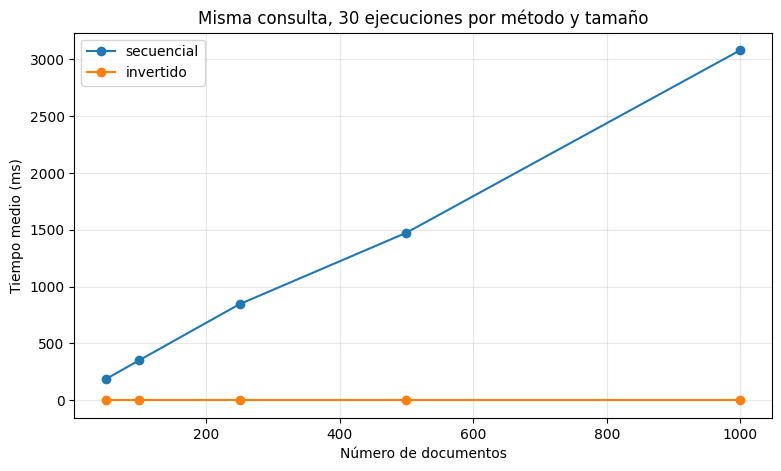

El término ausente obliga al método secuencial a examinar todos los tokens. Los subconjuntos son prefijos de los mismos identificadores originales. Se estima la memoria del corpus sumando el diccionario, los identificadores, las listas y cada token único compartido mediante internado; no es la memoria total del proceso. También se reporta el pico de asignaciones Python durante la construcción del índice con tracemalloc, que añade sobrecosto a esa construcción. El tamaño pickle mide almacenamiento serializado.

In [8]:
import tracemalloc
TAMANOS = [50, 100, 250, 500, 1000]
if len(corpus_b) < max(TAMANOS): raise ValueError('El corpus válido no alcanza 1.000 documentos.')
filas = []
CONSULTA_ESCALA = consultas['inexistente']
for n in TAMANOS:
    ids = sorted(corpus_b)[:n]
    sub = {i: corpus_b[i] for i in ids}
    tracemalloc.start()
    inicio = time.perf_counter_ns(); idx = construir_indice(sub)
    construccion_ms = (time.perf_counter_ns() - inicio)/1e6
    _, pico = tracemalloc.get_traced_memory(); tracemalloc.stop()
    assert busqueda_secuencial(CONSULTA_ESCALA, sub) == busqueda_indice(CONSULTA_ESCALA, idx)
    archivo_idx = DATA / f'indice_{n}.pkl'
    with archivo_idx.open('wb') as f: pickle.dump(idx, f, protocol=pickle.HIGHEST_PROTOCOL)
    fila = {'n': n, 'tokens': sum(map(len, sub.values())), 'construccion_ms': construccion_ms,
            'pico_construccion_MiB': pico/2**20, 'indice_disco_MiB': archivo_idx.stat().st_size/2**20,
            'textos_disco_MiB': sum((destino / f'{i}.txt').stat().st_size for i in ids)/2**20}
    unicos = set(t for tokens in sub.values() for t in tokens)
    fila['corpus_estimado_MiB'] = (sys.getsizeof(sub) + sum(sys.getsizeof(i) + sys.getsizeof(tokens) for i,tokens in sub.items()) + sum(map(sys.getsizeof, unicos)))/2**20
    del unicos
    for nombre, fn, estructura in [('secuencial', busqueda_secuencial, sub), ('invertido', busqueda_indice, idx)]:
        m = medir(fn, CONSULTA_ESCALA, estructura)
        fila[nombre + '_ms'] = m['media_ms']
        fila[nombre + '_desviacion_ms'] = m['desviacion_ms']
    filas.append(fila)
    del idx; gc.collect()
escala = pd.DataFrame(filas)
display(escala)
escala.to_csv(DATA / 'escalabilidad.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
for metodo in ('secuencial', 'invertido'):
    ax.plot(escala.n, escala[metodo + '_ms'], 'o-', label=metodo)
ax.set(xlabel='Número de documentos', ylabel='Tiempo medio (ms)', title='Misma consulta, 30 ejecuciones por método y tamaño')
ax.legend(); ax.grid(alpha=.3); plt.show()
display(Markdown('El término ausente obliga al método secuencial a examinar todos los tokens. Los subconjuntos son prefijos de los mismos identificadores originales. Se estima la memoria del corpus sumando el diccionario, los identificadores, las listas y cada token único compartido mediante internado; no es la memoria total del proceso. También se reporta el pico de asignaciones Python durante la construcción del índice con tracemalloc, que añade sobrecosto a esa construcción. El tamaño pickle mide almacenamiento serializado.'))

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

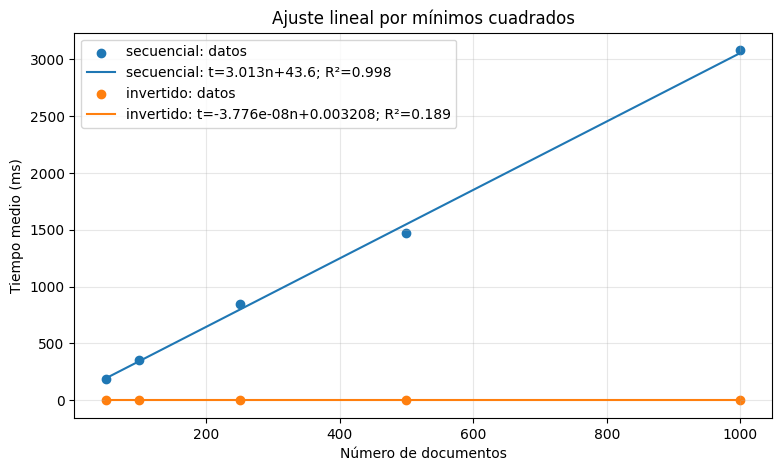

,metodo,a_ms_por_documento,b_ms,R2
0,secuencial,3.012906e+00,43.603735,0.998394
1,invertido,-3.775567e-08,0.003208,0.189240


**Secuencial:** $t(n)=3.01291n+(43.6037)$ ms, $R^2=0.9984$.

**Invertido:** $t(n)=-3.77557e-08n+(0.00320835)$ ms, $R^2=0.1892$.

**Interpretación.** La búsqueda secuencial tiene costo O(T), donde T es el total de tokens examinados. La relación con n será aproximadamente lineal solo si el tamaño medio de los libros es relativamente estable. Un R² bajo exige revisar esa variabilidad, la caché y el ruido del sistema; no demuestra por sí solo un cambio de complejidad.

El acceso esperado al diccionario es O(1), pero devolver una copia de los postings cuesta O(DF). Para el término inexistente, DF=0 y el tiempo debería ser casi constante: una pendiente pequeña y un R² bajo pueden reflejar ruido. AND, OR y NOT dependen del tamaño de los conjuntos; NOT también depende del universo de documentos. Construir el índice cuesta O(T) y requiere memoria adicional; ese costo se registra por separado y no se incluye en la latencia de consulta.

**Límites.** Se estudian cinco subconjuntos deterministas, no una muestra aleatoria de toda la colección; no se extrapolan tiempos a otros equipos. Se conservan encabezados y pies editoriales en ambos corpus para aplicar exactamente el mismo tratamiento. La deduplicación se realiza por identificador Gutenberg, no por similitud textual. Los resultados y ajustes se generan exclusivamente a partir de las ejecuciones reales.

In [9]:
ajustes = []
fig, ax = plt.subplots(figsize=(9, 5))
for metodo in ('secuencial', 'invertido'):
    x = escala.n.to_numpy(dtype=float); y = escala[metodo + '_ms'].to_numpy()
    a, b = np.polyfit(x, y, 1); pred = a*x+b
    sst = np.sum((y-y.mean())**2)
    r2 = 1-np.sum((y-pred)**2)/sst if sst else float('nan')
    ajustes.append({'metodo': metodo, 'a_ms_por_documento': a, 'b_ms': b, 'R2': r2})
    ax.scatter(x, y, label=f'{metodo}: datos')
    ax.plot(x, pred, label=f'{metodo}: t={a:.4g}n+{b:.4g}; R²={r2:.3f}')
ax.set(xlabel='Número de documentos', ylabel='Tiempo medio (ms)', title='Ajuste lineal por mínimos cuadrados')
ax.legend(); ax.grid(alpha=.3); plt.show()
display(pd.DataFrame(ajustes))
for fila in ajustes:
    display(Markdown(f"**{fila['metodo'].capitalize()}:** $t(n)={fila['a_ms_por_documento']:.6g}n+({fila['b_ms']:.6g})$ ms, $R^2={fila['R2']:.4f}$."))
display(Markdown("""**Interpretación.** La búsqueda secuencial tiene costo O(T), donde T es el total de tokens examinados. La relación con n será aproximadamente lineal solo si el tamaño medio de los libros es relativamente estable. Un R² bajo exige revisar esa variabilidad, la caché y el ruido del sistema; no demuestra por sí solo un cambio de complejidad.

El acceso esperado al diccionario es O(1), pero devolver una copia de los postings cuesta O(DF). Para el término inexistente, DF=0 y el tiempo debería ser casi constante: una pendiente pequeña y un R² bajo pueden reflejar ruido. AND, OR y NOT dependen del tamaño de los conjuntos; NOT también depende del universo de documentos. Construir el índice cuesta O(T) y requiere memoria adicional; ese costo se registra por separado y no se incluye en la latencia de consulta.

**Límites.** Se estudian cinco subconjuntos deterministas, no una muestra aleatoria de toda la colección; no se extrapolan tiempos a otros equipos. Se conservan encabezados y pies editoriales en ambos corpus para aplicar exactamente el mismo tratamiento. La deduplicación se realiza por identificador Gutenberg, no por similitud textual. Los resultados y ajustes se generan exclusivamente a partir de las ejecuciones reales."""))

### Discusión de los resultados obtenidos

El archivo oficial contiene **78,145 TXT no vacíos**, que se agrupan en **78,145 identificadores únicos**. Para los experimentos se conservaron 1.000 libros y sus identificadores originales.

Los resultados se comprobaron por igualdad exacta de conjuntos; todas las comparaciones completadas pasaron esa verificación.

**Secuencial:** a 50 documentos se midieron 187.260047 ms y a 1.000 documentos 3081.338197 ms. El ajuste es $t(n)=3.0129062n+(43.603735)$ ms, con $R^2=0.9984$.

El modelo lineal representa bien estos cinco puntos. El costo exacto depende de los tokens, por lo que libros de distinta longitud pueden alterar la relación con el número de documentos.

**Invertido:** a 50 documentos se midieron 0.003250 ms y a 1.000 documentos 0.003180 ms. El ajuste es $t(n)=-3.7755666e-08n+(0.0032083472)$ ms, con $R^2=0.1892$.

La consulta ausente devuelve cero postings: se espera un costo aproximadamente constante respecto de n. El R² de una recta no demuestra escalabilidad lineal cuando las mediciones son pequeñas y están dominadas por sobrecostos fijos y ruido; no se extrapola su pendiente.

A 1.000 libros se procesaron **80,792,398 tokens**. La búsqueda secuencial tardó aproximadamente **968,974.3 veces** el tiempo de la consulta con índice en esta medición. Este cociente excluye la construcción del índice y no resume consultas con DF alto.